<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Missing Data
---

### Learning Objectives
- Define MCAR, MAR, and NMAR.
- Describe various strategies for dealing with missing data.
- Understand the assumptions we make when using strategies to handle missing data.

### Credit
This lesson is adapted from a missing data workshop that Matt Brems presented at the Open Data Science Conference ([ODSC](https://odsc.com/)).  Check out his GitHub repo [here](https://github.com/matthewbrems/missing-data-workshop?fbclid=IwAR1LGjaIen-ITLndPN1ODV1lYZBvxsHDs0DgIaPkuxpXMsQRBT8eAPI-0sI).

In [1]:
# Import libraries.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statistics

# Set random seed.
np.random.seed(42)

In [2]:
# Bring in our data of age, partnered, children, and income data
# where income is linearly related to age, partnered, and children.
income = pd.read_csv('./data/income.csv') 
income_missing = pd.read_csv('./data/income_missing.csv') 

# Check out first 10 rows
income_missing.head(10)

,children,age,partnered,income
0,1,35.0,1,56531.361287
1,2,58.0,1,93026.182530
2,0,49.0,1,42693.010819
3,0,44.0,1,83680.128218
4,1,26.0,0,28845.520835
5,1,26.0,1,24898.840890
6,2,22.0,1,67152.008080
7,2,55.0,1,35047.373500
8,5,44.0,1,17245.869659
9,1,NaN,1,75749.529176


In [5]:
print(income_missing.shape)
income_missing.isnull().sum()

(100, 4)


children      0
age          30
partnered     0
income        0
dtype: int64

In [6]:
income_missing.isnull().mean()

children     0.0
age          0.3
partnered    0.0
income       0.0
dtype: float64

In [7]:
# create a function to compare histograms of original & imputed data
def compare_histograms(imputed_column, original_column, x_label, y_label = 'Frequency'):
    fig, (ax0, ax1) = plt.subplots(nrows = 2, ncols = 1, figsize = (16,9))

    # Set axes of histograms.
    mode = statistics.mode(imputed_column)
    rnge = max(original_column) - min(original_column)
    xmin = min(original_column) - 0.02 * rnge
    xmax = max(original_column) + 0.02 * rnge
    ymax = 40

    ax0.set_xlim(xmin, xmax)
    ax0.set_ylim(0, ymax)
    ax1.set_xlim(xmin, xmax)
    ax1.set_ylim(0, ymax)

    # Set top labels.
    ax0.set_title('Real Histogram', position = (0,1), ha = 'left', fontsize = 25)
    ax0.set_xlabel(x_label, position = (0,0), ha = 'left', fontsize = 25, color = 'grey', alpha = 0.85)
    ax0.set_ylabel(y_label, position = (0,1), ha = 'right', va = 'top', fontsize = 25, rotation = 0, color = 'grey', alpha = 0.85)
    ax0.set_xticks([])
    ax0.set_yticks([])

    # Generate top histogram.
    ax0.hist(original_column, bins = 15, color = '#185fad', alpha = 0.75, label = '')
    ax0.axvline(np.mean(original_column), color = '#185fad', lw = 5, label = 'True Mean')
    ax0.legend(prop={'size': 15}, loc = 1)

    # Set bottom labels.
    ax1.set_title('Imputed Histogram', position = (0,1), ha = 'left', fontsize = 25)
    ax1.set_xlabel(x_label, position = (0,0), ha = 'left', fontsize = 25, color = 'grey', alpha = 0.85)
    ax1.set_ylabel(y_label, position = (0,1), ha = 'right', va = 'top', fontsize = 25, rotation = 0, color = 'grey', alpha = 0.85)
    ax1.set_xticks([])
    ax1.set_yticks([])
    
    # Generate bottom histogram.
    ax1.hist(imputed_column, bins = 15, color = 'orange', alpha = 0.75, label = '', stacked = True)
    ax1.axvline(np.mean(original_column), color = '#185fad', lw = 5, label = 'True Mean')
    ax1.axvline(np.mean(imputed_column), color = 'darkorange', lw = 5, label = 'Imputed Mean')
    ax1.legend(prop={'size': 15}, loc = 1)

    plt.tight_layout();

### Method 1: Deductive Imputation

We use logical rules to fill in missing values.
- Survey asks if the respondent was the victim of a crime in the last twelve months.
- Respondent says no.
- Survey then asks if the respondent was the victim of a violent crime in the last twelve months.
- Respondent leaves this answer blank.

**Pros**:
- Can be used regardless of missingness type
- Requires no inference

**Cons**:
- Requires specific coding
- Can be time consuming
- May not be possible

### Method 2: Mean/Median/Mode Imputation

For any “NA” value in a given column, replace “NA” with the mean, median, or mode.

**Pros**:
- Quick
- Easy to implement
- Seems reasonable

**Cons**:
- Can significantly distort histogram
- Underestimates variance
- Should only be considered if data is MCAR

#### Mean Imputation

In [8]:
# Which columns have missing values?
income_missing.isnull().sum()

children      0
age          30
partnered     0
income        0
dtype: int64

In [9]:
# Let's impute missing values in the age column with the mean
mean_age = income_missing['age'].mean()

mean_age

39.5

In [10]:
income_missing['age_mean_imputed'] = income_missing['age'].fillna(mean_age)

In [11]:
income_missing[income_missing['age'].notnull()].describe()

,children,age,partnered,income,age_mean_imputed
count,70.000000,70.000000,70.000000,70.000000,70.000000
mean,1.842857,39.500000,0.785714,56001.445562,39.500000
std,1.500104,11.811012,0.413289,24157.867447,11.811012
min,0.000000,20.000000,0.000000,10688.919618,20.000000
25%,1.000000,28.000000,1.000000,42267.765610,28.000000
50%,1.000000,40.500000,1.000000,54008.299561,40.500000
75%,3.000000,49.000000,1.000000,75404.548096,49.000000
max,5.000000,59.000000,1.000000,105525.257095,59.000000


In [12]:
income_missing[income_missing['age'].isnull()].describe()

,children,age,partnered,income,age_mean_imputed
count,30.000000,0.0,30.000000,30.000000,30.0
mean,1.933333,NaN,0.700000,52455.902422,39.5
std,1.484014,NaN,0.466092,20312.710246,0.0
min,0.000000,NaN,0.000000,11954.707974,39.5
25%,1.000000,NaN,0.000000,40492.032967,39.5
50%,2.000000,NaN,1.000000,55512.459871,39.5
75%,3.000000,NaN,1.000000,64824.327745,39.5
max,5.000000,NaN,1.000000,93324.666459,39.5


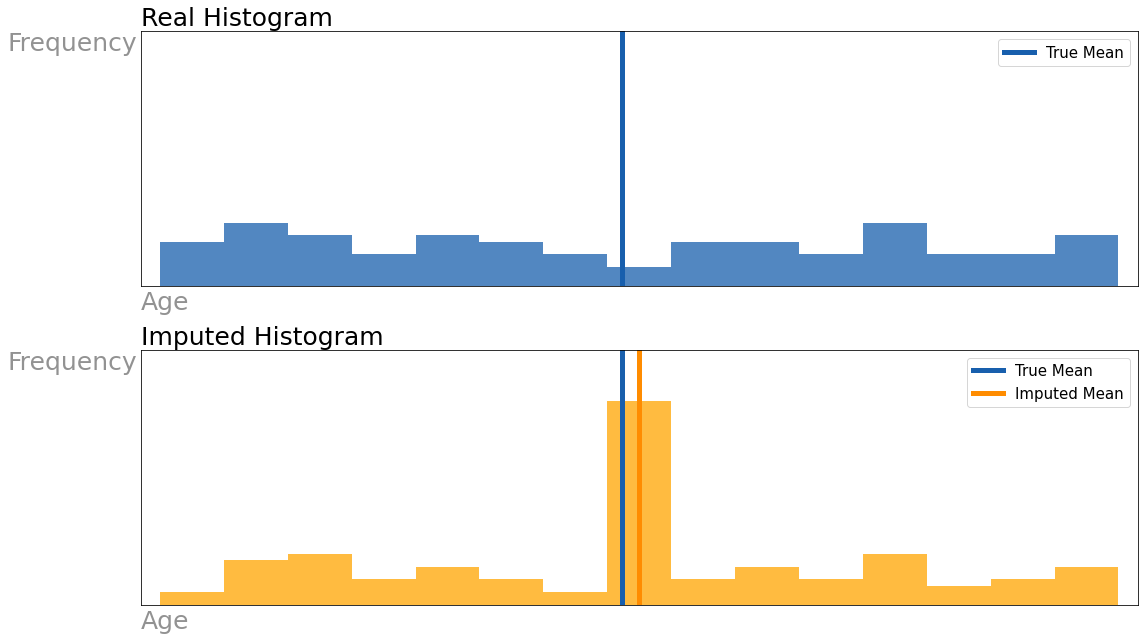

In [13]:
compare_histograms(imputed_column = income_missing['age_mean_imputed'],
                   original_column = income['age'],
                   x_label = 'Age',
                   y_label = 'Frequency')

We are underestimating the variance here.


Why is this a bad thing?
- If we underestimate variance in a confidence interval, our confidence interval gets smaller for the same level of confidence!
    - Our results artificially look more precise... but only because we imputed the mean!
- If we underestimate the variance in a hypothesis test, our p-value will artificially get smaller.
    - Our p-value may look significant... but only because we imputed the mean!

#### Median Imputation

In [14]:
# Let's impute missing values in the age column with the median
med_age = income_missing['age'].median()

In [17]:
income_missing['age_med_imputed'] = income_missing['age'].fillna(med_age)

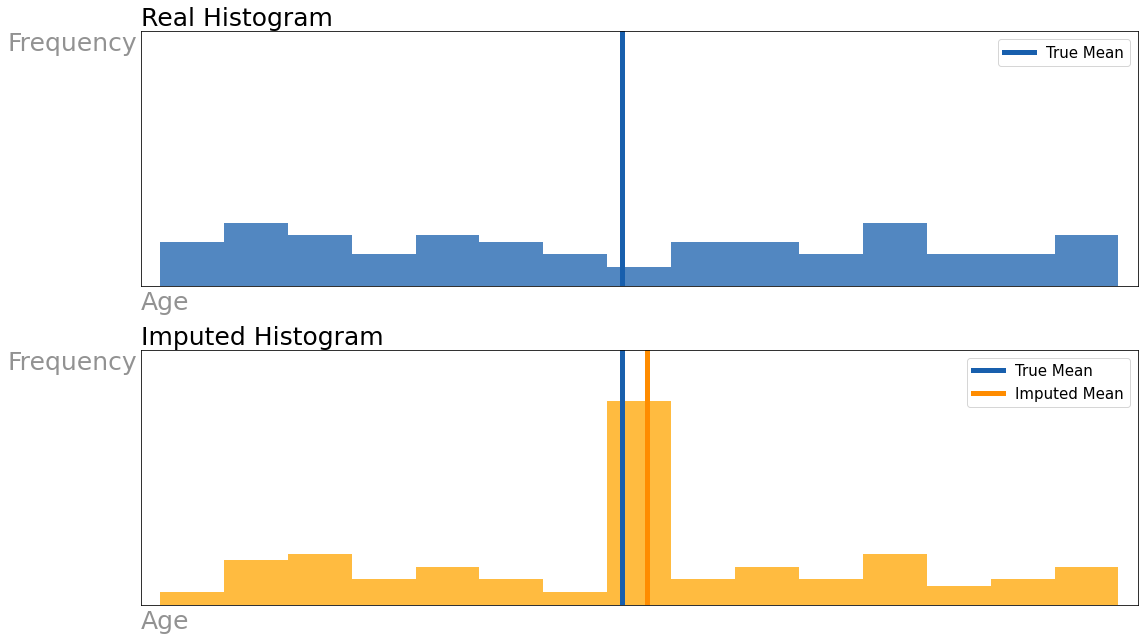

In [18]:
compare_histograms(imputed_column = income_missing['age_med_imputed'],
                   original_column = income['age'],
                   x_label = 'Age',
                   y_label = 'Frequency')

#### Mode Imputation

In [25]:
income_missing['age'].mode().values[0]

44.0

In [27]:
income_missing['age'].value_counts().index[0]

44.0

In [28]:
# Let's impute missing values in the age column with the mode
mode_age = 44

In [29]:
income_missing['age_mode_imputed'] = income_missing['age'].fillna(mode_age)

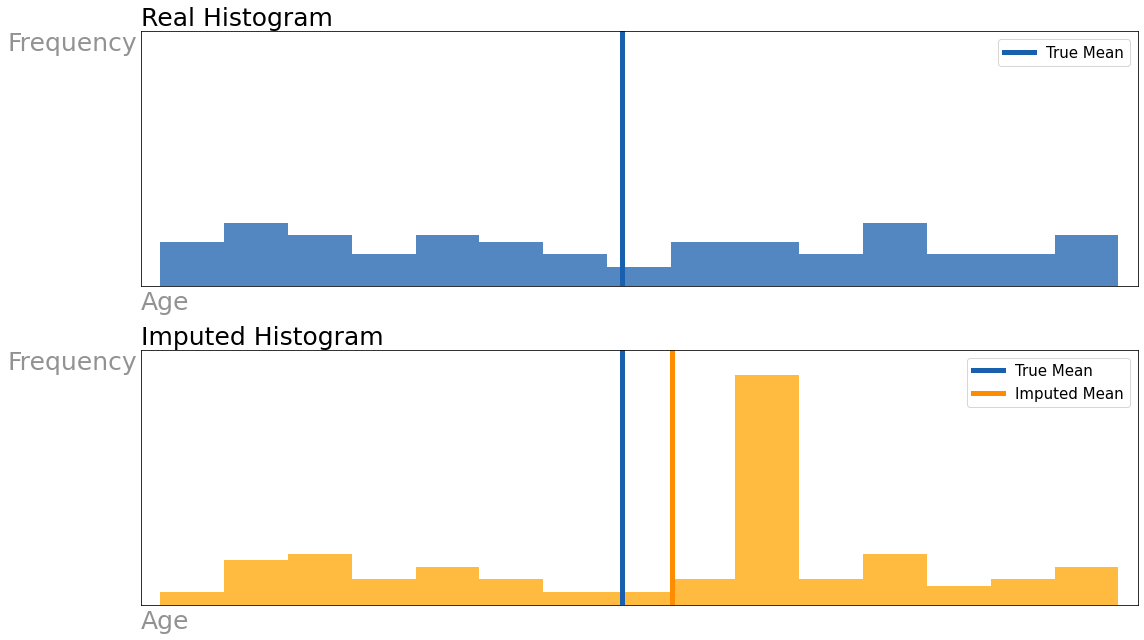

In [30]:
compare_histograms(imputed_column = income_missing['age_mode_imputed'],
                   original_column = income['age'],
                   x_label = 'Age',
                   y_label = 'Frequency')

### Make your life easier -> Simple Imputer in sklearn

Note: Train-test-split BEFORE doing this if you are going to model later to avoid data leakage!

Documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html#sklearn.impute.SimpleImputer).

In [31]:
# import simple imputer
from sklearn.impute import SimpleImputer

In [32]:
# re-load data
income_missing = pd.read_csv('./data/income_missing.csv')

income_missing.head()

,children,age,partnered,income
0,1,35.0,1,56531.361287
1,2,58.0,1,93026.182530
2,0,49.0,1,42693.010819
3,0,44.0,1,83680.128218
4,1,26.0,0,28845.520835


In [39]:
income_missing.age.median()

40.5

In [42]:
imputer = SimpleImputer(strategy = 'median', add_indicator=True)

In [43]:
imputer.fit_transform(income_missing)

array([[1.00000000e+00, 3.50000000e+01, 1.00000000e+00, 5.65313613e+04,
        0.00000000e+00],
       [2.00000000e+00, 5.80000000e+01, 1.00000000e+00, 9.30261825e+04,
        0.00000000e+00],
       [0.00000000e+00, 4.90000000e+01, 1.00000000e+00, 4.26930108e+04,
        0.00000000e+00],
       [0.00000000e+00, 4.40000000e+01, 1.00000000e+00, 8.36801282e+04,
        0.00000000e+00],
       [1.00000000e+00, 2.60000000e+01, 0.00000000e+00, 2.88455208e+04,
        0.00000000e+00],
       [1.00000000e+00, 2.60000000e+01, 1.00000000e+00, 2.48988409e+04,
        0.00000000e+00],
       [2.00000000e+00, 2.20000000e+01, 1.00000000e+00, 6.71520081e+04,
        0.00000000e+00],
       [2.00000000e+00, 5.50000000e+01, 1.00000000e+00, 3.50473735e+04,
        0.00000000e+00],
       [5.00000000e+00, 4.40000000e+01, 1.00000000e+00, 1.72458697e+04,
        0.00000000e+00],
       [1.00000000e+00, 4.05000000e+01, 1.00000000e+00, 7.57495292e+04,
        1.00000000e+00],
       [2.00000000e+00, 4.0500

### Method 3: Single Regression Imputation

Train a model on the rows of your data that are fully observed.
- Suppose I’m missing income for some people, but have observed age and highest level of education for everybody.
- X = age and highest level of education, Y = income.
- Fit a model.
- For any “NA” value in a given column, replace “NA” with predicted value from that model.

**Pros**:
- Seems reasonable
- A little more nuanced than mean/median/mode imputation

**Cons**:
- Still distorts histogram
- Underestimates variance
- Should only be considered if data is MCAR or MAR.

In [44]:
# re-load data
income_missing = pd.read_csv('./data/income_missing.csv') 

In [45]:
# Import linear regression
from sklearn.linear_model import LinearRegression

In [46]:
# Save new dataframe without any missing values
not_missing = income_missing[income_missing['age'].notnull()]

In [47]:
X = not_missing.drop(columns = 'age')
y = not_missing['age']

# Set up model
lr = LinearRegression()

# Fit
lr.fit(X, y)

LinearRegression()

In [48]:
# save indices of missing values
idxs = income_missing[income_missing['age'].isnull()].index

In [49]:
pred = lr.predict(income_missing.loc[idxs, X.columns])

In [50]:
income_missing.loc[idxs, 'age'] = pred

In [ ]:
# Impute missing values with the prediciton from the model
income_missing['age_regression_imputed'] = [income_missing.loc[i,'age'] if i not in missing_idx
     else model.predict(pd.DataFrame(income_missing.loc[i,['children', 'partnered', 'income']]).T)[0]
     for i in range(income_missing.shape[0])]

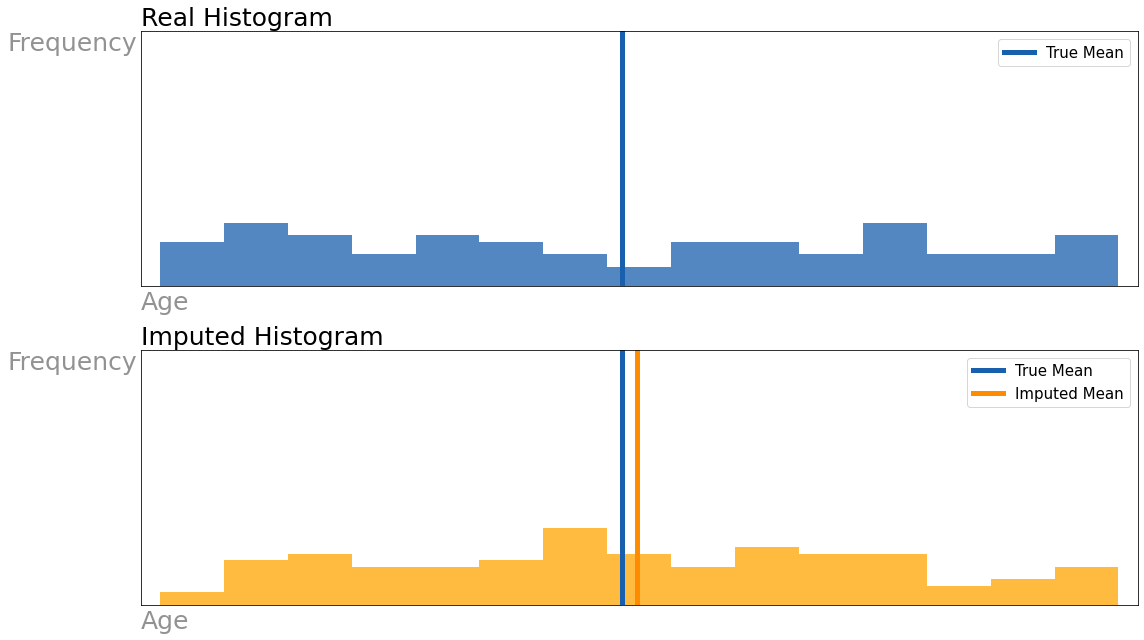

In [52]:
compare_histograms(imputed_column = income_missing['age'],
                   original_column = income['age'],
                   x_label = 'Age',
                   y_label = 'Frequency')

![](./images/deterministic_imputation.png)

[source](http://www.stat.columbia.edu/~gelman/arm/missing.pdf)

### Make your life easier -> Iterative Imputer in sklearn

Documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html#sklearn.impute.IterativeImputer).

From [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html#sklearn.impute.IterativeImputer): 
> Note: This estimator is still experimental for now: the predictions and the API might change without any deprecation cycle. To use it, you need to explicitly import enable_iterative_imputer:

```python
# explicitly require this experimental feature
from sklearn.experimental import enable_iterative_imputer  
# now you can import normally from sklearn.impute
from sklearn.impute import IterativeImputer
```

Again, make sure to fit this only on training data if you are using this for a model (you can transform testing data).

In [53]:
# imports
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression

In [54]:
# re-load data
income_missing = pd.read_csv('./data/income_missing.csv') 

In [55]:
imputer = IterativeImputer(estimator=LinearRegression())

In [56]:
imputer.fit_transform(income_missing)

array([[1.00000000e+00, 3.50000000e+01, 1.00000000e+00, 5.65313613e+04],
       [2.00000000e+00, 5.80000000e+01, 1.00000000e+00, 9.30261825e+04],
       [0.00000000e+00, 4.90000000e+01, 1.00000000e+00, 4.26930108e+04],
       [0.00000000e+00, 4.40000000e+01, 1.00000000e+00, 8.36801282e+04],
       [1.00000000e+00, 2.60000000e+01, 0.00000000e+00, 2.88455208e+04],
       [1.00000000e+00, 2.60000000e+01, 1.00000000e+00, 2.48988409e+04],
       [2.00000000e+00, 2.20000000e+01, 1.00000000e+00, 6.71520081e+04],
       [2.00000000e+00, 5.50000000e+01, 1.00000000e+00, 3.50473735e+04],
       [5.00000000e+00, 4.40000000e+01, 1.00000000e+00, 1.72458697e+04],
       [1.00000000e+00, 4.23702913e+01, 1.00000000e+00, 7.57495292e+04],
       [2.00000000e+00, 3.89213434e+01, 1.00000000e+00, 5.71769502e+04],
       [4.00000000e+00, 4.65827320e+01, 1.00000000e+00, 8.86604764e+04],
       [1.00000000e+00, 4.47573889e+01, 0.00000000e+00, 6.70892603e+04],
       [2.00000000e+00, 4.38576886e+01, 0.00000000e

In [57]:
it_inc_missing = pd.DataFrame(imputer.fit_transform(income_missing), columns = income_missing.columns)

it_inc_missing

,children,age,partnered,income
0,1.0,35.000000,1.0,56531.361287
1,2.0,58.000000,1.0,93026.182530
2,0.0,49.000000,1.0,42693.010819
3,0.0,44.000000,1.0,83680.128218
4,1.0,26.000000,0.0,28845.520835
...,...,...,...,...
95,1.0,40.000000,1.0,74090.088031
96,1.0,41.000000,1.0,52304.403273
97,3.0,37.000000,0.0,10688.919618
98,4.0,46.473431,0.0,68232.834868


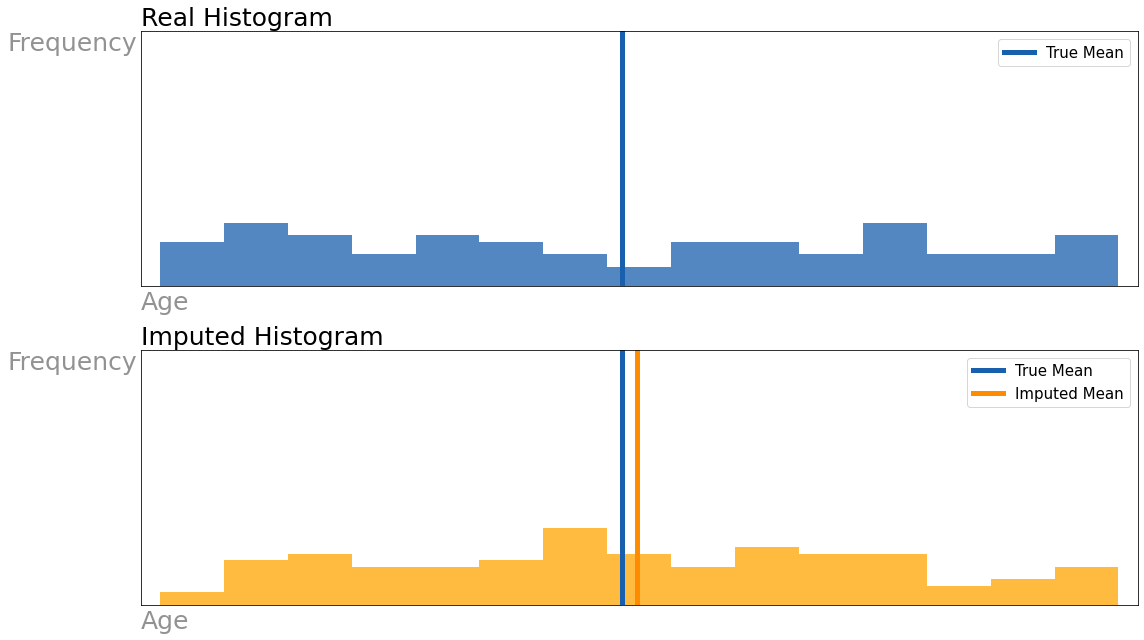

In [58]:
compare_histograms(imputed_column = it_inc_missing['age'],
                   original_column = income['age'],
                   x_label = 'Age',
                   y_label = 'Frequency')

### Method 4: Nearest Neighbors Imputation

Documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html#sklearn.impute.KNNImputer).

In [59]:
# import it
from sklearn.impute import KNNImputer

In [60]:
# re-load data
income_missing = pd.read_csv('./data/income_missing.csv') 

In [61]:
knn_imp = KNNImputer()

In [62]:
knn_inc_missing = pd.DataFrame(knn_imp.fit_transform(income_missing), columns = income_missing.columns)

knn_inc_missing.head()

,children,age,partnered,income
0,1.0,35.0,1.0,56531.361287
1,2.0,58.0,1.0,93026.182530
2,0.0,49.0,1.0,42693.010819
3,0.0,44.0,1.0,83680.128218
4,1.0,26.0,0.0,28845.520835


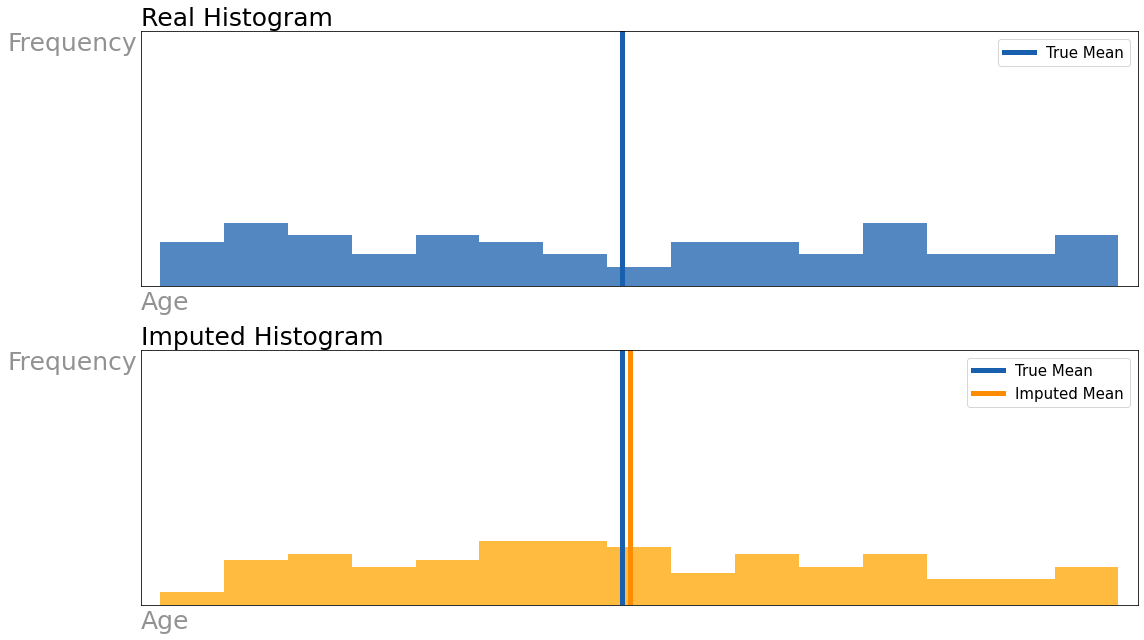

In [63]:
compare_histograms(imputed_column = knn_inc_missing['age'],
                   original_column = income['age'],
                   x_label = 'Age',
                   y_label = 'Frequency')

---

## Feature Union

In [64]:
# re-load data

income_missing = pd.read_csv('./data/income_missing.csv')

income_missing.head()

,children,age,partnered,income
0,1,35.0,1,56531.361287
1,2,58.0,1,93026.182530
2,0,49.0,1,42693.010819
3,0,44.0,1,83680.128218
4,1,26.0,0,28845.520835


In [65]:
from sklearn.preprocessing import FunctionTransformer

In [66]:
def get_mean_cols(df):
    # Return children and age
    return df[['children', 'age']]

get_mean_cols_tf = FunctionTransformer(get_mean_cols, validate = False)

In [67]:
get_mean_cols_tf.transform(income_missing).head()

,children,age
0,1,35.0
1,2,58.0
2,0,49.0
3,0,44.0
4,1,26.0


In [72]:
def get_median_cols(df):
    # return the partnered and income cols
    return df[['partnered', 'income']]

get_median_cols_tf = FunctionTransformer(get_median_cols, validate = False)

In [73]:
from sklearn.pipeline import Pipeline

mean_pipe = Pipeline([
    # function
    ('get_mean_cols_tf', get_mean_cols_tf),
    # mean imputer
    ('imputer', SimpleImputer(strategy='mean'))
])

median_pipe = Pipeline([
    # function
    ('get_median_cols_tf', get_median_cols_tf),
    # median imputer
    ('imputer', SimpleImputer(strategy='median'))
])

In [75]:
# Creating a Feature Union
# Helps concatenate results of different transformers along second axis (columns)
from sklearn.pipeline import FeatureUnion

feature_union = FeatureUnion([
    ('mean_pipe', mean_pipe),
    ('median_pipe', median_pipe)
    # OHE
])

feature_union.fit_transform(income_missing)

array([[1.00000000e+00, 3.50000000e+01, 1.00000000e+00, 5.65313613e+04],
       [2.00000000e+00, 5.80000000e+01, 1.00000000e+00, 9.30261825e+04],
       [0.00000000e+00, 4.90000000e+01, 1.00000000e+00, 4.26930108e+04],
       [0.00000000e+00, 4.40000000e+01, 1.00000000e+00, 8.36801282e+04],
       [1.00000000e+00, 2.60000000e+01, 0.00000000e+00, 2.88455208e+04],
       [1.00000000e+00, 2.60000000e+01, 1.00000000e+00, 2.48988409e+04],
       [2.00000000e+00, 2.20000000e+01, 1.00000000e+00, 6.71520081e+04],
       [2.00000000e+00, 5.50000000e+01, 1.00000000e+00, 3.50473735e+04],
       [5.00000000e+00, 4.40000000e+01, 1.00000000e+00, 1.72458697e+04],
       [1.00000000e+00, 3.95000000e+01, 1.00000000e+00, 7.57495292e+04],
       [2.00000000e+00, 3.95000000e+01, 1.00000000e+00, 5.71769502e+04],
       [4.00000000e+00, 3.95000000e+01, 1.00000000e+00, 8.86604764e+04],
       [1.00000000e+00, 3.95000000e+01, 0.00000000e+00, 6.70892603e+04],
       [2.00000000e+00, 3.95000000e+01, 0.00000000e

### Missing Indicator Column

We can add a column about which values were imputed/missing and use that as a feature in our model. This can help when there is a pattern in what is missing and our target and may help our model.

See another example of this [here](https://nbviewer.jupyter.org/github/justmarkham/scikit-learn-tips/blob/master/notebooks/09_add_missing_indicator.ipynb).

There are several ways we can do this:
1. Set `add_indicator = True` in Simple Imputer or Iterative Imputer if you are using these:
```python
imputer = SimpleImputer(add_indicator=True)
imputer.fit_transform(X)
```
2. Use the `MissingIndicator` transformer in [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.impute.MissingIndicator.html#sklearn.impute.MissingIndicator).

In [ ]:
# re-load data
income_missing = pd.read_csv('./data/income_missing.csv') 

---
## Bonus (For Further Study)
---

### Method 5: Multiple Imputation

If we want to account for the randomness in our data, we can fill in missing values with some amount of randomness/uncertainty.

Replacing an NA with one value treats things like we know the true value.

Therefore, we need to impute multiple times.
- We will make multiple copies (say 10) of our dataset.
- We will use [random regression imputation](https://statisticsglobe.com/regression-imputation-stochastic-vs-deterministic/) to generate one value for each NA in each dataset.
- Once each of our 10 datasets are complete, we will do our “final model” or “final analysis” on each dataset.
- We will then combine the results of our multiple models together, just like we aggregate results in an ensemble model.

![](./images/proper_imputation.png)


If you’re **generating predictions**, you can just average your predictions together in a regression problem or select the plurality class in a classification problem.

If your goal is to do **inference** (e.g. understand how X affects Y) and are fitting a linear model to each dataset, then you get a slope and y-intercept for each model.
- There are a set of tools, called Rubin’s rules, that will allow you to take the slopes and y-intercepts from each model and combine them together.
- Check out documentation in the repo if interested!

[IterativeImputer](https://scikit-learn.org/stable/modules/impute.html#multiple-vs-single-imputation) in sklearn can help with this!

### Method 6: Pattern Submodel Approach

Big Picture: We will break our dataset into subsets based on missingness pattern. We will then build one model on each subset, creating many different models.

![](./images/pattern_submodel.jpeg)

[image source](https://opendatascience.com/data-imputation-beyond-mean-median-and-mode/)

**Pros**:
- The pattern submodel method will outperform imputation methods when your data are NMAR, and will perform about as well as imputation methods when your data are MCAR or MAR.
- You can generate predictions for test observations containing missing data.
- It does not require missingness assumptions!

**Cons**:
- This is not a well-understood method for inference.

Read more about this method [here](https://academic.oup.com/biostatistics/article/21/2/236/5092384).

See an example of this [here](https://github.com/sarahmercaldo/MissingDataAndPrediction) - note that this example is done in R.